# Funktioner og differentiering
Vi lægger ud med at bruge lidt tid på at forstå hovedideerne fra **calculus**, eller infinitesimalregning, som er den samlede betegnelse for differential- og integralregning.

Denne del er for det meste en opfriskning af matematik, som I burde have set før på B-niveau.

Calculus giver en ramme for at forstå mekanikken af matematiske funktioner. Calculus hjælper os med at:
* Forstå hældning i forskellige punkter
* Finde ekstreme punkter i en funktion

> **NB:** Denne notebook indeholder celler, der fejler *med vilje*. Celler mærket **⚠️ Forventet fejl** skal fejle, så vi kan øve os i at læse fejlmeddelelser. Alle andre celler skal kunne køres oppefra og ned uden fejl.


> ### Dagens lektion
> * **Emne**: Funktioner og differentiering - hældning, sekanter, grænseværdier og tangenter.
> * **Matematik (opfriskning fra B-niveau)**: lineære funktioner, andengradsfunktioner, differenskvotienten.
> * **Python i dag**: `np.linspace`, `plt.plot`, `sympy.symbols`, `sympy.limit`, `sympy.diff`, `.subs()`.
> * **Husk**: Kør cellerne oppefra og ned. Opfører noget sig mærkeligt: *Runtime → Restart session and run all*.


En lineær funktion kan skrives som
$f(x) = ax + b$.

En andengradsligning kan skrives som $f (x) = ax^2 + bx + c$

Vi starter med at oprette et gennemgående problem, som vi hele tiden henviser til i dette afsnit. Problemet er ikke et økonomisk, så vi kan fokusere på matematikken for nu. Lad os antage, at vi får følgende ligning, som beskriver banens bane, efter at den er sparket af en fodboldspiller:

$y = (-x^2) + 3x -1$

$x$ er tid i sekunder, mens $y$ er boldens vertikale position. Naturligvis vil vi gerne kende den højeste position, bolden nåede, og hvornår det skete. Vi kan tegne ligningen og estimere resultatet visuelt, men hvis vi ønsker det præcise tidspunkt og vertikale position skal vi bruge calculus. I dette kursus undersøger vi de forskellige beregningskoncepter, der er nødvendige for at bygge op til at være i stand til at finde dette punkt.

Lad os starte med at visualisere denne funktion.



**Øvelse**

* Brug numpy.linspace() til at generere en Numpy array indeholdene **100** værdier fra **0** til **3** og tildel til $x$.
* Transformer $x$ ved at anvende funktionen: $y = (-x^2) + 3x -1$. Tildel resultatet til $y$
* Brug pyplot.plot() til at generere et linjediagram med $x$ på x-aksen og $y$ på y-aksen.
* Overvej, hvordan man kan udregne max højden, og det præcise tidspunkt det skete.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

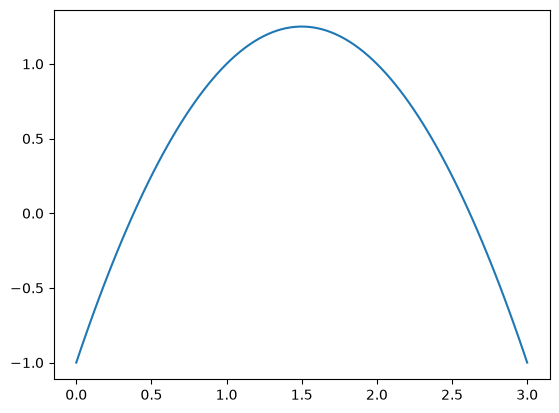

In [2]:
x = np.linspace(0, 3, num=100)
y = (-x**2)+3*x-1

plt.plot(x,y)

#### Calculus og lineær algebra
Før vi dykker ned i at analysere kurven for en bolds højde, skal vi forstå nogle få centrale koncepter først. Vi vil udforske disse koncepter ved hjælp af enkle, lige linjer først og derefter opbygge at anvende disse begreber på kurver. En enkel, lige linje defineres tydeligere som en lineær funktion. Alle lineære funktioner kan skrives i følgende form:

$y = ax + b$

For en bestemt lineær funktion, er a og b konstante værdier, mens $x$ og $y$ er variabler. $y = 3x + 1$ og $y = 5$ er begge eksempler på lineære funktioner.

Lad os fokusere på funktionen $y = 3x + 1$ indtil videre. Denne funktion multiplicerer enhver $x$ værdi, vi tilføjer med 3 og forhøjer derefter værdien med 1.

Lad os starte med at få en geometrisk forståelse af lineære funktioner. Nedenfor finder du et billede, der kan hjælpe dig med at forstå, hvordan linjen forskydes eller ændres, når du ændrer værdier på $a$ og/eller $b$.
* Hvordan ændres linjen, når du holder $a$ fast, men varierer $b$?
* Hvordan ændres linjen, når du holder $b$ fast, men varierer $a$?
*	Hvilken værdi styrer linjens stejlhed?
*	Hvad sker der med linjen, når $a$ er indstillet til 0?

In [3]:
# np.arange(start, stop) laver en række af heltal - stop er IKKE inkluderet, så vi bruger 7 for at nå op til 6
x = np.arange(-5, 7)
print(x)

[-5 -4 -3 -2 -1  0  1  2  3  4  5  6]


In [4]:
y = 3*x + 1
print(y)

[-14 -11  -8  -5  -2   1   4   7  10  13  16  19]


In [5]:
import IPython

In [6]:
iframe = '<iframe src="https://www.desmos.com/calculator/efglhmyz8f" width="1000px" height="500px" style="border: 1px solid #ccc" frameborder=0></iframe>'
IPython.display.HTML(iframe)

/content


#### Linjens ændringshastighed (rate of change)
Fra det forrige trin kan vi fortælle, at konstanten $a$ bestemmer, hvor *stejl* linjen er.
Når $a$ er lig med 0, er linjen helt flad og er parallel med x-aksen. Når $a$ og $b$ begge er indstillet til 0, svarer linjen til x-aksen.

$a$-værdien styrer en linjes hældning, mens $b$-værdien styrer en linjens y-skæring. Disse udtryk vil blive uddybet yderligere. Y-skæringspunktet er den værdi, hvor linjen skærer y-aksen. Når man fastholder $a$, men varierede b, har du muligvis bemærket, at det punkt, hvor linjen krydsede y-aksen, varierede. Linjen skærer y-aksen når $x$ er 0. For $y = 3x + 1$, er y-skæringspunktet:

$f(0) = 3(0) + 1 = 1$

Mens y-skæringspunktet beskriver, hvor en linje skærer y-aksen, beskriver hældningen linjens stejlhed. I det sidste trin, når vi indstiller $a$ til en positiv værdi, er y-værdierne steget efterhånden som x-værdierne steg. Når vi indstiller $a$ til en negativ værdi, falder y-værdierne, som x-værdierne steg. Når $a$ var 0, var y-værdien konsistent (og tilsvarende y-skæringspunktet).


* Positiv hældningsgrad: Linjen stiger, når man bevæger sig fra venstre mod højre.
* Negativ hældningsgrad: Linjen falder, når man bevæger sig fra venstre mod højre.
* Nul hældningsgrad: Linjen er vandret.
* Udefineret hældningsgrad: Linjen er lodret.

En anden måde at tænke på hældning er **ændringshastighed** (*rate of change*). Ændringshastigheden er, hvor meget y-aksen ændrer sig, for en bestemt ændring i x-aksen.

$a = \frac{\text{change in y}}{\text{change in x}} = \frac{\Delta y}{\Delta x}$

Her er hældningsberegningen mellem punkterne (1,4) og (4,13), som begge er punkter på linjen $y = 3x + 1$:

$a = \frac{\text{change in y}}{\text{change in x}} = \frac{13-4}{4-1} = 3$

Når der skal skrives unikke $x$ og $y$ koordinater, tilføjes der normalt et indekstal (subscript). For eksempel kan punkterne (1,4) og (4,13) fra den sidste beregning være kaldt ($x_1, y_1$) og ($x_2, y_2$). Hvis vi ikke specificerer hvad ($x_1, y_1$) og ($x_2, y_2$) er, handler de som variabler. Vi understreger dette yderligere i billedet til dette trin, og når vi undersøger i beregningerne i næste trin.

Det følgende billede indeholder en visualisering af $y = 3x + 1$ med 2 koordinater fremhævet. Prøv at variere $x_1$ og $x_2$ værdierne og observer visualiseringen af ændringshastigheden. Både koordinaterne ($x_1, y_1$) og ($x_2, y_2$) er fremhævet på linjen. Beregningen af ændringshastigheden vises også i plottets titel. Du vil bemærke, at
ligegyldigt hvad koordinaterne er, er ændringshastigheden mellem dem altid 3.


In [7]:
iframe = '<iframe src="https://www.desmos.com/calculator/jh1zb3n9al" width="1000px" height="500px" style="border: 1px solid #ccc" frameborder=0></iframe>'
IPython.display.HTML(iframe)

#### Ændringshastighed og funktionens hældning
Hvis vi beregner ændringshastigheden mellem punkter på en linje, vil den altid være lig funktionens hældning. Lad os vise dette for det mere generelle tilfælde. I det følgende repræsenterer ($x_1, y_1$) og ($x_2, y_2$) 2 tilfædlige koordinater på en linje:

$y_1 = ax_1 + b$

$y_2 = ax_2 + b$

Vi kan trække begge disse ligninger fra for at få:

$y_1 - y_2 = ax_1 - ax_2 + b - b$

$y_1 - y_2 = a(x_1 - x_2)$

$a = (y_1 - y_2)/(x_1 - x_2)$

$y_1 - y_2$ repræsenterer her $\Delta y$, og $x_1 - x_2$ repræsenterer $\Delta x$. Lad os udregne hældningen for nogle flere punkter der ligger på $y = 3x + 1$.


**Øvelse**
* Skriv en funktion med navnet slope(), der beregner ændringshastigheden mellem to koordinater.
* Denne funktion skal acceptere 4 parametre, der repræsenterer 2 x-værdier og 2 y-værdier for 2 forskellige punkter: $x1$, $x2$, $y1$, $y2$
* Beregn ændringshastigheden mellem (0,1) og (4,13) og tildel
til slope_1.
* Beregn ændringshastigheden mellem (5,16) og (-1, -2) og tildel til slope_2.
* Beregn ændringshastigheden mellem 2 punkter fra visualiseringen



In [8]:
def slope(x1, x2, y1, y2):
  a = (y2-y1)/(x2-x1)
  return a

In [9]:
slope_1 = slope(0,4,1,13)

In [10]:
slope_2 = slope(5,-1,16,-2)

In [11]:
print(slope_1)
print(slope_2)

3.0
3.0


## Ikke-lineære funktioner
Indtil videre har vi arbejdet med lineære funktioner, hvor vi kan bestemme hældningen på funktion fra selve ligningen. Men hvis vi vender tilbage til vores ligning med boldens bane, vil du bemærke, at det ikke matcher formularen $y = ax + b$:

$y = -(x^2) + 3x - 1$

Dette skyldes, at denne funktion er en **ikke-lineær funktion**. Ikke-lineære funktioner repræsenterer ikke lige linjer - de repræsenterer kurver som den, vi fremlagde i den første del af denne session. Outputs fra en ikke-lineær funktion er ikke proportionale med inputværdierne $x$. Et inkrement i $x$ resulterer ikke i konstant inkrement i $y$.

Når $x$ hæves til en styrke, der ikke er lig med $1$, har vi en ikke-lineær funktion. Her er nogle flere eksempler på ikke-lineære funktioner:

$y = x^3$

$y = x^3 + 3x^2 + 2x -1$

$y = \frac{1}{-x^2}$

$y = \sqrt{x}$

I det følgende billede kan du observere, hvordan hældningen ændrer sig med forskellige værdier for $x_1$ og $x_2$ her bruger jeg lige $a$ og $b$ pga interface.

In [12]:
iframe = '<iframe src="https://www.desmos.com/calculator/wiirw9ca6h" width="1000" height="500px" style="border: 1px solid #ccc" frameborder=0></iframe>'
IPython.display.HTML(iframe)


#### Sekanten
Efterhånden som i ændrede $x_1$ og $x_2$, varierede hældningen mellem de 2 punkter drastisk. Fordi lineære funktioner har en konstant hældning igennem, og dermed kender vi hældningen for alle punkter på linjen. Hvis vi vidste, at forholdet mellem temperatur og vindhastighed var lineær, kunne vi forudsige, hvad vindhastigheden ville være ved en hvilken som helst temperatur ved at prøve to punkter og beregne hældningen.

Hvis forholdet i stedet var ikke-lineært, kunne vi ikke forudsige, hvad vindhastigheden ville være ved en hvilken som helst bestemt temperatur ved blot at måle 2 punkter og regne hældning mellem dem (fordi hældningen ændrer sig drastisk afhængigt af hvilke 2 punkter du vælger). Når vi beregner hældningen mellem 2 punkter på en kurve, beregner vi i virkeligheden hældningen af linjen, der skærer begge disse punkter.

Som I ved er ligningen for en lineær funktion $y = ax + b$ - for sekanter og tangenter kalder vi hældningen $m$. Hvis vi kender værdierne for $m$, $x$ og $y$, kan vi beregne $b$, eller y-skæringen, ved hjælp af noget aritmetik. Lad os gå gennem beregningen for linjen, der forbinder punkterne ved x-værdierne $0$ og $1$.

Først angiver vi, hvad vi ved.

$y = -(x^2) + 3x -1$

$x_1 = 0$

$x_2 = 1$

Vi bruger $y = -(x^2) + 3x -1$ til at beregne $y_1$ og $y_2$.

$y_1 = 0 + 0 - 1 = -1$

$y_2 = -1 +3 -1 = 1$

Vi bruger koordinaterne (x,y) til at løse hældningen.

$m = \frac{y_2 - y_1}{x_2 - x_1} = \frac{2}{1} = 2$

Fordi både ($x_1, y_1$) og ($x_2, y_2$) er punkter på linjen, kan vi bruge både den ene og den anden til at beregne y-skæringsværdien ($b$).

$y_1 = mx_1 + b$

$-1 = 2(0) + b$

$b = -1$

Endelig kan vi bruge hældningen og y-skæringen til at udforme ligningen for
linjen, der forbinder begge punkter:

$y = 2x -1$

En linje, der skærer 2 punkter på en kurve, er kendt som en **sekantlinje**. Lad os øve at skabe nogle sekantlinjer til vores kurve.Vi har lavet lidt forarbejde til at danne funktionen **draw_secant()**, som lige nu bare plotter vores ikke-lineære funktion mellem x-værdierne -20 og 30.


**øvelse**

Lad os prøve at definere funktionen **draw_secant()**, som accepterer 2 x-værdier som en liste
og tegner sekantlinjen, der forbinder disse 2 punkter. Denne funktion skal:

* Bestemme y-værdierne for disse 2 x-værdier ved hjælp af vores ikke-lineære funktion.
* Beregne hældningen mellem disse 2 punkter.
* Beregne y-skæringspunktet ved hjælp af aritmetik.
* Plotte sekantlinjen ved hjælp af farven "grøn".
* Vise alle plottene i funktionen.

Brug funktionen draw_secant() til at generere 3 plot:
* En visualisering af sekantlinjen mellem x-værdierne 3 og 5.
* En visualisering af sekantlinjen mellem x-værdierne 3 og 10.
* En visualisering af sekantlinjen mellem x-værdierne 3 og 15


In [13]:
def draw_secant(x_values):
    # draw function
    x = np.linspace(-20,30,100)
    y = -1*(x**2) + x*3 - 1
    plt.plot(x,y)

    # hent x1 og x2
    x1 = x_values[0]
    x2 = x_values[1]

    # udregn y-værdier fra x1 og x2
    y1 = -1*(x1**2) + x1*3 - 1
    y2 = -1*(x2**2) + x2*3 - 1

    # hældning m og intercept udregnes her
    m = (y2-y1)/(x2-x1)
    b = y1-m*x1

    # formel for sekanten
    s = m*x+b

    plt.plot(x,s, c='green')

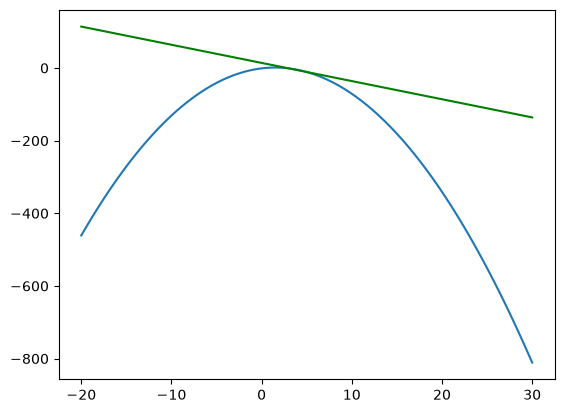

In [14]:
draw_secant([3,5])

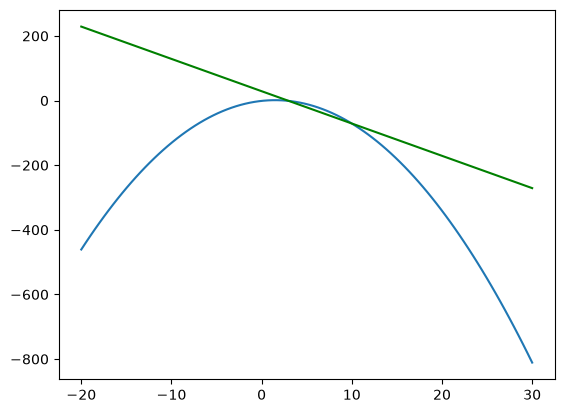

In [15]:
draw_secant([3,10])

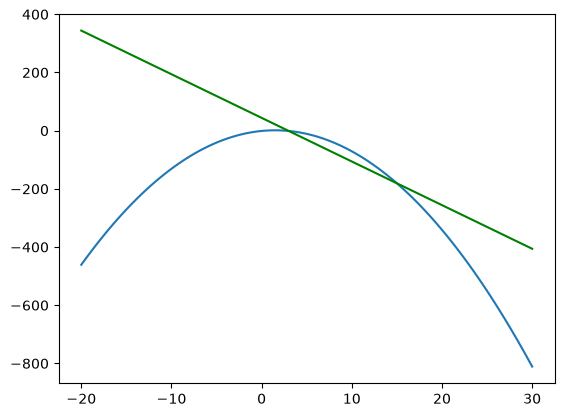

In [16]:
draw_secant([3,15])

### Kurvens hældning
I ovenstående plottede vi sekantlinjer mellem den faste $x_1$ værdi og stadig større $x_2$ værdier. Da afstanden mellem $x_1$ og $x_2$ var lille, *krydsede* sekantlinjen nemt med vores kurve. Da vi øgede afstanden mellem de 2 x-værdier, begyndte sekantlinjen at afvige fra vores kurve. Denne observation er kritisk for at forstå hvordan hældning fungerer for kurver.

Hældningen på en kurve på et bestemt punkt forstås bedst som hældningen af sekantlinjen med stadig mindre intervaller af $[x_1, x_2]$. Jo mindre forskellen mellem $x_1$ og $x_2$, jo mere præcist tilnærmer sekantlinjen hældningen på det punkt på vores kurve.

#### Kurvens hældningsværdi
Når $x_1$ og $x_2$ har samme værdi, er hældningsværdien **udefineret**. Dette skyldes, at **deling med 0** ingen mening har i matematiske beregninger.

$m = \frac{-1--1}{3-3} = \frac{0}{0} = \text{undefined}$

Når $x_2$ nærmer sig $x_1$ fra hvilken som helst side af kurven, er hældningen af den sekante linje imidlertid nær -3. Her er en tabel, der viser hældningsværdierne for stadig smallere huller mellem $x_2$ og $x_1$:


$$
\begin{matrix}
\hline
\textbf{x2} & \textbf{x1} & \textbf{m} \\ \hline
2.9         & 3           & -2.9       \\
2.99        & 3           & -2.99      \\
2.999       & 3           & -2.999     \\
3.01        & 3           & -3.01      \\
3.001       & 3           & -3.001     \\
3.0001      & 3           & -3.0001    \\ \hline
\end{matrix}
$$


Selvom vi ikke kan beregne hældningen på det punkt, hvor $x_0 = x_1 = 3$, kan vi udlede fra tabellen og grafen fra det sidste trin, at den nærmer sig -3. Denne værdi er kendt som **den øjeblikkelige vækstrate**, fordi den beskriver hældningen på et bestemt punkt. I lineære funktioner, er den øjeblikkelige vækstrate på ethvert punkt på linjen den samme. I
ikke-lineære funktioner, beskriver den øjeblikkelige ændringshastighed grafens stejlhed af funktionen på et bestemt punkt.

Denne linje er kendt som **tangenten**, og i modsætning til sekantlinjen skærer den kun vores funktion på ét tidspunkt. Indtil videre har vi arbejdet med sekantlinjer, der forbinder 2 punkter, der er tættere sammen. Du kan tænke på tangentlinjen som sekantlinjen når begge punkter er de samme. For nu bliver vi nødt til at lære at arbejde med den udefenerede værdi, som vi får når vi prøver at beregne tangentlinjen direkte.


## Tangenten og kurvens hældning
Nu har vi prøvet at fiksere et første punkt på vores kurve, trukket en sekant linje mellem det første punkt og et andet punkt og observeret, hvad der skete, da vi flyttede det andet punkt tættere på det første punkt langs kurven. Jo større intervallet mellem de 2 punkter på x-aksen er, desto mere afviger sekantlinjens hældning fra kurvens hældning. Jo tættere intervallet er, desto mere begyndte sekantlinjen at matche stejlheden ved det første punkt på kurven.

I denne del formaliserer vi ideen om hældning yderligere og ser, hvordan man **beregner hældningen for ikke-lineære ligninger på et givet punkt**. Når du gennemgår resten af dette kursus, anbefaler at følge den matematik, der præsenteres, ved hjælp af blyant og papir. Vi starter med at introducere en matematisk notation, der formaliserer den observation, vi lige har lavet.

Det kan være du har hørt tidligere (gymnasiet) om det under betegnelsen **differenskvotient**. Differenskvotienten er funktionstilvæksten ($y_2-y_1$) divideret med $(x_2-x_1)$ som tit også skrives som $h$. Og dermer:

 $$a_s=\frac{y_2-y_1}{x_2-x_1}=\frac{f(x_0+h)-f(x_0)}{(x_0+h)-x_0}=\frac{f(x_0+h)-f(x_0)}{h}$$

 eller

 $$a_s=\frac{\Delta y}{h}=\frac{f(x_0+h)-f(x_0)}{h}$$

 Hvis vi forsøger at "samle" vores $x_1$ og $x_2$ værdier – dvs. $x_1 = x_2$ –  så løber vi ind i division-med-nul-problemet:

$$m = \frac{f(x_2)-f(x_1)}{x_2 - x_1} = \frac{0}{0}$$

Selvom hældningen er udefineret når $x_1$ og $x_2$ er ækvivalente, vil vi stadig være i stand til at redegøre for og begrunde, hvilken værdi hældningen nærmer sig når $x_1$ nærmer sig $x_2$. For at gøre det skal vi omformulere problemet som en **grænseværdi** (*limit*). Grænseværdien beskriver værdien, som en funktion nærmer sig, når inputvariablen til funktionen nærmer sig en bestemt værdi. I vores tilfælde er inputvariablen $x_2$ og vores funktion er $m = \frac{f(x_2)-f(x_1)}{x_2 - x_1}$. Den følgende matematiske notation formaliserer udsagnet "når $x_2$ nærmer sig $3$, nærmer hældningen mellem $x_1$ og $x_2$ sig $-3$", ved brug af grænseværdien:

$$\lim_{x2\to3}\frac{f(x_2)-f(x_1)}{x_2 - x_1} = -3$$

$\lim_{x_2\to3}$ er en anden måde at sige "når $x_2$ nærmer sig $3$". Fordi vi fikserede $x_1$ til $3$, kan vi erstatte $x_1$ med $3$ i funktionen:

$$\lim_{x_2\to3}(\frac{f(x_2)-f(3)}{x_2 - 3}) = \lim_{x2\to3}\frac{f(x_2)+1}{x_2 - 3} = -3$$

Formelt kan vi også sige, at **differentialkvotienten** er grænseværdien af **differenskvotienten** for h gående mod 0.

$$a_t=\lim_{h\to0}(a_s)=\lim_{h\to0}(\frac{\Delta y}{h})$$

Vi skal stadig bevise, at denne grænseværdi faktisk svarer til $-3$, hvilket vi vil bruge resten af dagens session til at kigge på.



#### Grænseværdier
Der er to slags grænseværdier - **definerede grænseværdier** og **udefinerede grænseværdier**. Som du nok kan gætte, var den grænseværdi, vi kiggede på i den sidste afsnit, en udefineret grænseværdi, fordi det at indsætte $3$ som $x_2$ resulterer i en udefineret værdi. En defineret grænseværdi kan evalueres bare ved at erstatte værdien i grænseværdi.

$$
\begin{matrix}
\hline
\textbf{x2} & \textbf{x1} & \textbf{m} \\ \hline
2.9         & 3           & -2.9       \\
2.99        & 3           & -2.99      \\
2.999       & 3           & -2.999     \\
3.01        & 3           & -3.01      \\
3.001       & 3           & -3.001     \\
3.0001      & 3           & -3.0001    \\ \hline
\end{matrix}
$$

Lad os starte med at forstå, hvordan definerede grænser fungerer. Når den resulterende værdi af en grænseværdi defineres til den værdi, inputvariablen nærmer sig, siger vi, at grænseværdien er defineret. Ovenstående er en tabel med værdier, der viser hældningerne af sekantlinjerne mellem tættere og tættere punkter på $x_1 = 3$:


For at beregne hver af disse hældninger brugte vi begge værdier i hældningsligningen. Her er beregningen for hældningen af sekantlinjen mellem punkterne ved $x_1 = 3$ og $x_2 = 2.9$ hvor $f(x) = -(x^2) + 3x -1$:

$$m = \frac{f(2.9) - f(3)}{2.9-3} = -2.9$$

Vi kan faktisk omskrive hver af disse som definerede grænseværdier. For eksempel beskriver den følgende definerede grænseværdi hældningen af sekantlinjen mellem de samme 2 punkter:

$$\lim_{x2\to2.9}\frac{f(x_2) - f(x_1)}{x_2-x_1}$$

Siden vi fikserede $x_1$ til værdien $3$, kan vi erstatte $x_1$ med $3$ og $f(x_1)$ med $-1$:

$$\lim_{x2\to2.9}\frac{f(x_2) - (-1)}{x_2-3}$$

For at løse for grænseværdien kan direkte indsætte $2.9$ for $x_2$. Dette skyldes, at grænseværdien er defineret for den specifikke værdi ($2.9$) som inputvariablen nærmer sig ($x_2$). Mere præcist: fordi funktionen er et polynomium og derfor kontinuert i punktet, er grænseværdien lig med funktionsværdien — direkte indsættelse er derfor tilladt her. Når vi kan erstatte inputvariablen med den værdi, den nærmer sig i grænseværdien, konverteres problemet til et almindeligt aritmetisk problem:

$$\frac{f(2.9) - (-1)}{2.9-3} = -2.9$$

Forhåbentlig har denne proces vist, hvordan vi kan løse udefinerede grænseværdier som den, vi præsenterede i første afsnit. **Ved at omskrive og konvertere en udefineret grænseværdi til en defineret grænseværdi, kan vi løse grænseværdien ved hjælp af direkte substitution og standard aritmetik**.

Før vi dykker ned i, hvordan man konverterer en udefineret grænseværdi til en defineret grænseværdi, skal vi lige undersøge, hvordan man beregner grænseværdier ved hjælp af Python for at verificere vores tilgang.


#### Sympy og calculus
SymPy-pakken har en række funktioner, der lader os beregne grænseværdier. Syntaks for SymPy følger ret nøje matematisk notation. For at starte er vi nødt til at importere pakken og bruge sympy.symbols() til at definere de variabler, vi ønsker at arbejde med, som symboler for at SymPy kan operere med dem:

In [17]:
# Importering af sympy
import sympy

Indtil nu har vi primært visualiseret en funktion ved at generere mange $x$ værdier (og definerede dem som objektet x), transformerede disse $x$ værdier til $y$ værdier (og definerede dem som objektet y), ved at benytte basic Python aritmetik operatorer og ved hjælp af matplotlib til at plotte begge lister af tal:

In [18]:
# Med numpy er x en samling af konkrete tal
x = np.linspace(0, 3, 100)
print(type(x))

<class 'numpy.ndarray'>


I SymPy er arbejdsgangen anderledes, og de Python-variabler, vi bruger, holder ikke direkte specifikke værdier. I SymPy linkes Python-variabler direkte til variabler i matematik. Vi udtrykker en matematisk funktion som en transformation af Python-variablen. Når man benytter sympy.symbols() og tildeler x, peger x på et specielt SymPy-objekt (ikke en liste):

In [19]:
# Definer symboler vha. SymPy
x,y = sympy.symbols('x y')

In [20]:
# Vurdering af hvilket form for Python objekt x er nu
print(type(x))

<class 'sympy.core.symbol.Symbol'>


Det vi skal nu er at skrive den matematiske funktion i SymPy. Vi bruger standard Python-aritmetiske operatorer til dette:

In [21]:
# Definer funktion x^2 + 3x
y = (-x**2)+3*x-1

In [22]:
y

-x**2 + 3*x - 1

**Øvelse:**

* Prøv at udtrykke $y = x^2 + 1$ ved at bruge '**' for at skrive $x^2$.
* Visualiser y ved hjælp af print() funktionen. Hvad er resultatet?
* Hvad sker der, når du kører $y = 3(x)$ i Python?

In [23]:
#Definer symboler i SymPy
x,y = sympy.symbols('x y')

Note om sympy funktionalitet. Modsat numpy, er SymPy lavet til at visualisere matematiske løsninger grafisk, og vil derfor fungere anderledes med print-funktionen. Forskel kan ses herunder:

In [24]:
# Med SymPy funktionalitet
y = x**2 + 1

In [25]:
# Korrekt måde at vise med sympy
y

x**2 + 1

In [26]:
# Sympy og print
print(y)

x**2 + 1


Og øvelsens sidste spørgsmål - hvad sker der, når du kører $y = 3(x)$?


In [27]:
# ⚠️ Forventet fejl — denne celle skal fejle
# Hvad sker der her? Kør cellen og læs fejlmeddelelsen nedefra og op
y = 3(x)

<>:3: SyntaxWarning: 'int' object is not callable; perhaps you missed a comma?
<>:3: SyntaxWarning: 'int' object is not callable; perhaps you missed a comma?
/var/folders/7v/frqfmbs922n1szkk4rqhmnz00000gp/T/ipykernel_16365/4116406961.py:3: SyntaxWarning: 'int' object is not callable; perhaps you missed a comma?
  y = 3(x)


TypeError: 'int' object is not callable

Python læser `3(x)` som *"kald tallet 3 som en funktion med argumentet x"* - og tal kan ikke kaldes, så vi får en `TypeError: 'int' object is not callable`. I matematik er $3(x)$ underforstået multiplikation, men i Python skal gange altid skrives eksplicit: `3*x`. Det er en af de mest almindelige fejl, når man oversætter matematik til kode.


In [28]:
# Udskriv formler til LaTex (markdown) format
sympy.latex(y)

'x^{2} + 1'

Indsat i markdown LaTex: $x^{2} + 1$

#### Flere nyttige SymPy-funktioner
Udover at definere og omskrive udtryk har SymPy en række funktioner, vi får brug for i øvelserne og resten af kurset:

* `sympy.expand()` udvider et udtryk - fx $(x+2)^2$ til $x^2 + 4x + 4$.
* `sympy.simplify()` forkorter og reducerer et udtryk mest muligt.
* `sympy.solve()` løser en ligning - den forventer formen $udtryk = 0$, så fx $x^2 = 25$ omskrives først til $x^2 - 25 = 0$.


In [29]:
# expand: udvid et udtryk
print(sympy.expand((x + 2)**2))

# simplify: reducer et udtryk mest muligt
print(sympy.simplify((x**2 - 25) / (x - 5)))

# solve: løs ligningen x**2 = 25 (omskrevet til formen x**2 - 25 = 0)
print(sympy.solve(x**2 - 25, x))

x**2 + 4*x + 4
x + 5
[-5, 5]


#### Grænseværdier i SymPy
Når vi har defineret variablerne og den matematiske funktion i SymPy, bruger vi sympy.limit() funktionen til at beregne grænseværdien. Denne funktion tager 3 parametre:
* Den funktion, vi søger grænseværdien til
* Inputvariablen
* Den værdi, som inputvariablen nærmer sig

Herfra arbejder vi med nogle nye grænseproblemer for at forstå de grundlæggende ideer. Lad os sige, at vi ønskede at løse følgende definerede grænseværdi:

$$\lim_{x\to1}x^2 + 1$$

For dette problem er inputvariablen $x$ og grænsekriteriet er $\lim{x\to1}$. Her kan man se, hvordan dette kan udtrykkes i SymPy:

In [30]:
# Med formel direkte i SymPy funktion
# første parameter er jeres funktion, anden del er inputvariablen (x), og tredje parameter er den værdi, inputvariblen nærmer sig ved den grænseværdi der skal udregnes.
limit_one = sympy.limit(x**2 + 1, x, 1)

In [31]:
limit_one

2

In [32]:
# Med predefineret formel
# Definer funktion
y = x**2 + 1
#udregn grænseværdi
limit_two = sympy.limit(y, x, 1)

In [33]:
limit_two

2

Lad os øve at bruge SymPy.

**Øvelse:**
* Brug SymPy til at bekræfte at $\lim_{x_2\to2.9}\frac{f(x_2) - (-1)}{x_2 -3} = -2.9$. Du skal definere $x_2 = 2.9$ samt $f(x) = - (x^2) + 3x - 1$ før du passerer grænsefunktionen i sympy.limit().
* Resultatet af grænseværdiberegningen defineres som objekt **limit_one**. Visualiser ved hjælp af print() funktionen.

In [34]:
# Definer x2 som symbol
x2 = sympy.symbols('x2')

# definer vores grænsefunktion
f_lim = (((-(x2**2)+3*x2-1))-(-1))/(x2-3)

# brug limit funktionen til at finde grænseværdien af vores f_lim når x2 nærmer sig 2.9
limit_one = sympy.limit(f_lim, x2, 2.9)

print(limit_one)

-2.89999999999999


In [35]:
# med SymPy visualiseringsstil
limit_one

-2.89999999999999

Sympy har også en funktion til at udskifte symboler med en konstant (et bestemt tal)

In [36]:
# Definer funktion
f_x = -(x**2)+3*x-1

In [37]:
# definer symboler
x, x1, x2 = sympy.symbols('x, x1, x2')

In [38]:
# Definer x som en konstant
f_x1 = f_x.subs(x, 3)

In [39]:
# værdien af y (f_x1) når x er = 3
f_x1

-1

## Egenskaber for grænseværdier
SymPy beregner $-2.9$ som hældningen på sekantlinjen, der matcher vores beregning ved hjælp af hældningsformlen. Før vi kan konvertere udefinerede grænseværdier til definerede grænseværdier, skal vi først forstå nogle  egenskaber ved grænseværdier. Ved hjælp af disse egenskaber kan vi omdanne udefinerede grænseværdier til definerede grænseværdier og løse dem. Her er den første egenskab:

#### Grænseværdier i opdelt funktion med addering og subtraktion

$$\lim_{x\to a}[f(x) + g(x)] = \lim_{x\to a}f(x) + \lim_{x\to a}g(x)$$

Denne egenskab giver os mulighed for at opdele grænseværdier, der opsummeres i deres individuelle komponenter. Dette gælder også for subtraktion:


$$\lim_{x\to a}[f(x) - g(x)] = \lim_{x\to a}f(x) - \lim_{x\to a}g(x)$$

Vi kan anvende disse regler for at opdele følgende grænseværdi i mindre komponenter:

$$\lim_{x\to 1}[3x^2 + 3x - 3]$$

Selvom dette er en defineret grænseværdi, og vi kan løse det ved hjælp af direkte erstatning, er det et godt eksempel for at forstå, hvordan man anvender disse egenskaber. Ved at anvende den egenskab, vi lige har lært, opdeles ligningen i:

$$\lim_{x\to 1}[3x^2] + \lim_{x\to 1}[3x] - \lim_{x\to 1}[3]$$

Lad os nu indsætte $x = 1$ i hver af disse grænsetermer.

$$3 + 3 - 3 = 3$$

Selvom vi ikke dykker ned i beviserne for disse grænsegenskaber i denne session, kan du læse mere om dem [her](https://tutorial.math.lamar.edu/Classes/CalcI/LimitProofs.aspx#Extras_Limit_LimitProp). Lad os bruge SymPy til at bekræfte dette resultat.

#### Opdeling af led ganget med en konstant

Den anden egenskab giver os mulighed for at opdele led, der ganges med en konstant:

$$\lim_{x \to a} [cf(x)] = c \lim_{x \to a} f(x)$$

Anvender vi den på grænseværdien ovenfor, bliver den til:

$$3 \lim_{x \to 1} [x^2] + 3 \lim_{x \to 1} [x] - 3 \lim_{x \to 1} [1]$$

og direkte erstatning giver samme svar: $3 + 3 - 3 = 3$.

Bemærk: SymPy anvender selv disse regler internt, når `limit()` udregner en grænseværdi - vi deler den op én gang nedenfor for at se, hvad der sker under motorhjelmen. Konstantreglen afprøver I selv i øvelserne.


**Øvelse**

* Brug SymPy til at udregne $lim_{x\rightarrow 1}[3x^2 + 3x -3]$.
* Tildel resultatet til **limit_two**, og visualiser ved hjælp af print() funktionen.

In [40]:
# Definer x som symbol
x = sympy.symbols('x')

In [41]:
# Udregn grænseværdien når x nærmer sig 1
limit_two = sympy.limit(3*(x**2)+3*x-3, x, 1)

In [42]:
# Print
print(limit_two)

3


Opdel $3x^2 +3x -3$

In [43]:
# Grænseværdierne for den opdelte funktion (med x=1)
#Første del af funktionen
lim1 = sympy.limit(3*(x**2), x, 1)

# Anden del af funktionen
lim2 = sympy.limit(3*x, x, 1)

# Tredje del af funktionen
lim3 = sympy.limit(-3, x, 1)

# Grænseværdi for den samlede funktion
lim1 + lim2 + lim3

3

Denne operation fortæller os dermed, at jo nærmere x er på 1, jo nærmere vil y være på 3. Dette kan også skrives som $f(1) = 3$

#### Fra udefineret til defineret grænseværdi
For at afslutte denne session, kan vi konvertere den oprindelige udefinerede grænseværdi, der beregnede hældningen ved $x = 3$, til en defineret grænse:

$$\lim_{x_2 \to 3} \frac{f(x_2) + 1}{x_2 - 3} =$$

Fordi $f(x) = -(x^2) + 3x - 1$, kan vi udvide $f(x_2)$.

$$\lim_{x_2 \to 3} \frac{-x_2^2+3x_2 -1 + 1}{x_2 - 3}$$

Dette kan reduceres til:

$$\lim_{x_2 \to 3} \frac{-x_2^2+3x_2 }{x_2 - 3}$$

Vi kan stadig ikke indsætte direkte for at løse denne grænse på grund af nævneren. Vi skal finde en tilgang til at annullere nævneren eller konvertere den til en form, der giver os mulighed at indsætte $3$ for $x_2$. Hvis sætter $x_2$ udenfor parentes (faktoriserer) i tælleren, kan vi se noget interessant:

$$\lim_{x_2 \to 3} \frac{x_2(-x_2 + 3) }{x_2 - 3}$$

Hvis vi også faktoriserer $-1$, kan vi annullere $x_2 -3$ fra nævneren med den samme term i tælleren:

$$\lim_{x_2 \to 3} \frac{-x_2(x_2 - 3) }{x_2 - 3}$$

Dette kan omskrives til:

$$\lim_{x_2 \to 3} -x_2$$

Nu kan vi indsætte direkte hvilket giver os $-3$. I dette tilfælde behøvede vi ikke at bruge egenskaberne af grænser, som vi kiggede på tidligere. I den næste del ser vi på hvordan vi kan udlede den generelle funktion, der giver os hældningen til enhver tid på kurven, og der bliver nødt til at bruge disse egenskaber. Lad os for nu tjekke hvad vi lige har set på "i hånden" ved hjælp af SymPy.


**Øvelse**

- Brug SymPy til at finde $\lim_{x_2 \to 3} \frac{f(x_2) + 1}{x_2 - 3}$
- Gem løsningen som **limit_four**

In [44]:
# Definer funktion
f_x2 = -(x2**2)+3*x2-1

# Brug SymPy til at finde grænseværdien når x2 = 3
limit_four = sympy.limit((f_x2+1)/(x2-3), x2, 3)

In [45]:
limit_four

-3

In [46]:
(f_x2+1)/(x2-3)

(-x2**2 + 3*x2)/(x2 - 3)

In [47]:
sympy.simplify((f_x2+1)/(x2-3))

-x2

## Sympy i praksis - Beregning og plot af tangenten (med manuelle steps)

Hvordan beregner og plotter vi (med de værktøjer vi har indtil videre) tangenten for $x_0 = 0.5$ i en funktion som hedder $f(x) = -x^2 + 3x - 1$?

$x_0$ refererer til begyndelsesværdien.

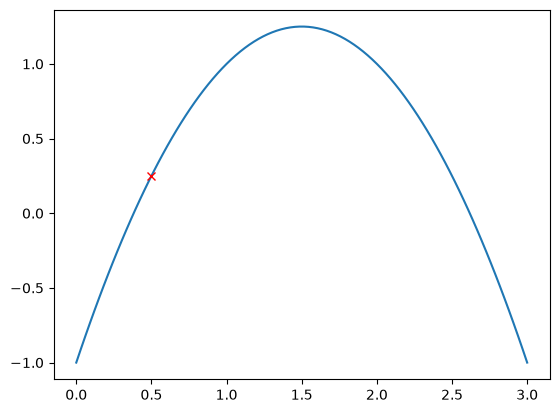

In [48]:
# Eksempel med tangent hvor x0 = 0.5
#Definer x som et rum
x = np.linspace(0, 3, num=100)
# Definer y som funktion
y = -(x**2)+3*x-1

# Plot funktionen
plt.plot(x,y)
# Marker et punkt på x,y akserne
plt.plot(0.5, 0.25, 'x', color='red')

Først defineres $x_0$​ som $0.5$, og $y0$​ beregnes ved brug af funktionen $f(x)=−x^2+3x−1$

In [49]:
# definer x0 som 0.5
x0 = 0.5

# Definer y0 som en funktion af x0
y0 = -(x0**2)+3*x0-1

# Vis y0
print(y0)

0.25


 Husk at vi kan beregne hældning i $x_0$

 $$m=\frac{y_2-y_1}{x_2-x_1}=\frac{f(x_0+h)-f(x_0)}{(x_0+h)-x_0}=\frac{f(x_0+h)-f(x_0)}{h}$$

 eller

 $$m=\frac{\Delta y}{h}=\frac{f(x_0+h)-f(x_0)}{h}$$


 Præcis, $h$ er den lille ændring i $x$-værdien, og $m$ er hældningen af tangenten, som findes ved at beregne grænseværdien af differenskvotienten

SymPy importeres, og symboler $x0$​ og $h$ defineres.

In [50]:
# opstilling af differenskvotient
#importering af sympy
from sympy import symbols, diff, solve, limit, simplify, expand # importer det, vi bruger, fra SymPy

#Definer symboler
x0, h = symbols('x0, h')

Funktionen $f(x0)$ defineres igen symbolsk

In [51]:
# Definer funktion
f_x0 = -(x0**2)+3*x0-1

In [52]:
#Vis funktionen af x0
f_x0

-x0**2 + 3*x0 - 1

Funktionen $f(x0+h)$ beregnes ved at erstatte $x0$​ med $x0+h$.

In [53]:
# Udskift x0 med x0+h
f_x0h = f_x0.subs(x0, x0+h)

In [54]:
# vis funktionen med x0+h
f_x0h

3*h + 3*x0 - (h + x0)**2 - 1

Differenskvotienten $m=\frac{f(x_0+h)−f(x_0)}{h}$ udregnes

In [55]:
# differenskvotienten - hældningen kalder vi m, som i formlen ovenfor
m = (f_x0h-f_x0)/h

In [56]:
m

(3*h + x0**2 - (h + x0)**2)/h

Grænseværdien af differenskvotienten beregnes, når $h$ nærmer sig 0 for at finde hældningen af tangenten.

In [57]:
# Udregning af grænseværdi
m_x0 = limit(m, h, 0)

In [58]:
m_x0

3 - 2*x0

Hældningen af tangenten evalueres ved $x0=0.5$.

In [59]:
# Udskift x0 med 0.5
m_x0.subs(x0, 0.5)

2.00000000000000

y-skæringen $b$ for tangenten findes.

In [60]:
# tangent -  Almindlig lineær funktion (fx_t) = mx + b; Vi kan indsætte fo x0 og y0

# 0.25 = 2*0.5 + b

b = 0.25 - 2*0.5
print(b)

-0.75


Dermed er vores tangent i $x_0$: $t = 2x - 0.75$ og nu kan vi også plotte det

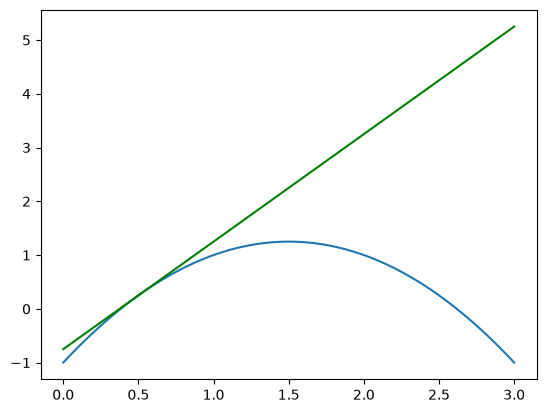

In [61]:
#Definer x som et rum
x = np.linspace(0, 3, num=100)
# definer funktionen af y
y = -(x**2)+3*x-1

#Plot x og y
plt.plot(x,y)

# definer tangent funktionen
t = 2*x - 0.75

# Plot tangenten
plt.plot(x,t, color='green')

# Simpleste tilgang til visualisering af tangent vha. SymPy, NumPy og Matplotlib

In [62]:
import numpy as np
import matplotlib.pyplot as plt

In [63]:
from sympy import symbols, diff, limit

# Definer x som symbol
x = symbols('x')

#Definer funktionen f_x
f_x = (-x**2)+3*x-1

In [64]:
# Beregn den afledte af f(x)
f_prime = diff(f_x, x)

In [65]:
# Vis f_prime
f_prime

3 - 2*x

In [66]:
# Evaluer den afledte ved x = 2
tangent_slope = f_prime.subs(x, 2)

In [67]:
# Vis den afledte
tangent_slope

-1

In [68]:
# Løs f(x) ved x = 2
f_at_x = f_x.subs(x, 2)

In [69]:
# Vis position af y ved x=2
f_at_x

1

In [70]:
# Generer x-værdier for funktionen
x_vals = np.linspace(-10, 10, 400)

# Generer y-værdier med udgangspunkt i den opstillede funktion
# y_vals skal matche den ligning der søges løst
y_vals = (-x_vals**2)+3*x_vals-1

In [71]:
# Beregn y-værdier for tangenten ved x=2
y_tangent = tangent_slope * (x_vals - 2) + f_at_x

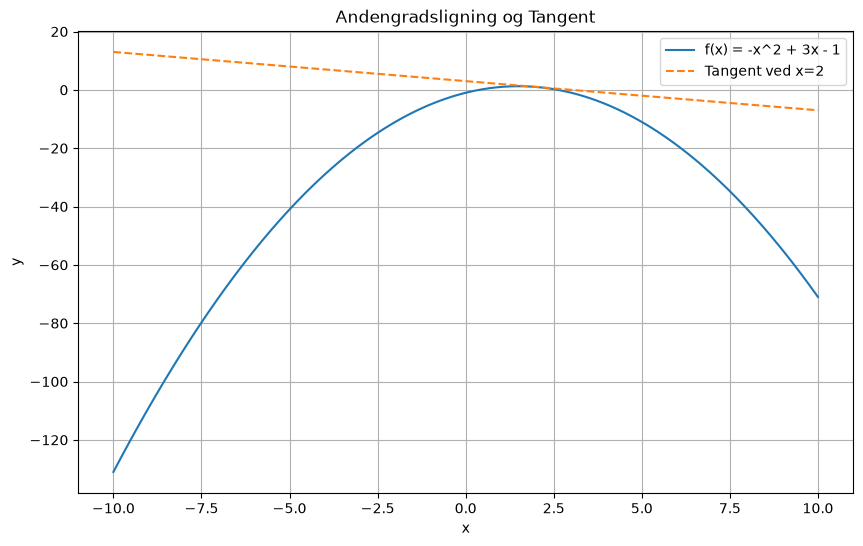

In [72]:
# Lav et plot
plt.figure(figsize=(10, 6))

#plot andengrandsligning
plt.plot(x_vals, y_vals, label='f(x) = -x^2 + 3x - 1')

#plot tangent
plt.plot(x_vals, y_tangent, label='Tangent ved x=2', linestyle='--')

#plot xlabel
plt.xlabel('x')

#Plot y-label
plt.ylabel('y')

# Giv grafen en titel
plt.title('Andengradsligning og Tangent')

# Giv grafen en legend
plt.legend()

# Lav et gridsystem for grafen
plt.grid(True)

#Vis grafen
plt.show()

## Det vigtigste fra i dag

**Funktioner og hældning**
* Calculus hjælper os med at forstå stejlheden af en funktion i forskellige punkter og finde dens ekstreme punkter.
* En lineær funktion er en lige linje: $y = ax + b$, hvor $a$ styrer hældningen og $b$ y-skæringen.
* Hældning er ændringshastighed: $m = \frac{y_2 - y_1}{x_2 - x_1}$ for to punkter. Når $x_1 = x_2$, er hældningen udefineret (division med 0).
* Ikke-lineære funktioner (fx $y = x^3$, $y = \sqrt{x}$) repræsenterer kurver - outputtet er ikke proportionalt med inputtet, så hældningen afhænger af, hvor på kurven man måler.
* En **sekant** skærer kurven i to punkter. **Tangenten** rører kurven i netop ét punkt, og dens hældning er kurvens øjeblikkelige ændringshastighed i det punkt.

**Grænseværdier**
* En grænseværdi beskriver den værdi, en funktion nærmer sig, når inputvariablen nærmer sig en bestemt værdi - også selvom funktionen er udefineret i selve punktet.
* Notationen $\lim_{x_2\to3}\frac{f(x_2)-f(x_1)}{x_2 - x_1} = -3$ formaliserer: "når $x_2$ nærmer sig $3$, nærmer hældningen sig $-3$".
* En defineret grænseværdi kan evalueres ved direkte indsættelse; en udefineret (fx $\frac{0}{0}$) kan ofte omskrives (faktorisering og forkortelse) til en defineret.
* Egenskaber: sum-/differensreglen $\lim[f \pm g] = \lim f \pm \lim g$ og konstantreglen $\lim[cf(x)] = c\lim f(x)$.

**SymPy**
* `sympy.symbols()` kobler Python-variabler til matematiske symboler; `sympy.limit(funktion, variabel, værdi)` udregner grænseværdier; `.subs()` indsætter konkrete tal.
* Tangentens hældning fandt vi som grænseværdien af differenskvotienten $m=\frac{f(x_0+h)-f(x_0)}{h}$ for $h \to 0$ - og `sympy.diff()` gør det hele i ét kald.
